## Trabajo pratico integrador 
## Estadistica y Exploración de Datos II
### Alumna: Sol Josefina Mercado | 38.442.698


### Temática: Analisis sobre la actividad física y la quema de calorias, como dueña de gimnasio y entrenadora este analisis puede ser de utilidad para mis clientes.

#### Algunas preguntas para EDA: 
* ¿Qué hace que un entrenamiento queme más calorías? 
* ¿Qué factores explican cuántas calorías quema una persona en una sesión de gimnasio? 
* ¿Importa más el tipo de entrenamiento o cómo se entrena (duración e intensidad)?

In [1]:
# carga del dataset
'''
El dataset: Gym Members Exercise Dataset (Vala Khorasani, Kaggle, 2024): 
kaggle.com/datasets/valakhorasani/gym-members-exercise-dataset. 
Tiene 973 filas y 15 columnas, y cada fila es un socio y su sesión de entrenamiento.
'''
import pandas as pd
df = pd.read_csv("data/gym_members_exercise_tracking.csv")
df.head(3)

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,Male,88.3,1.71,180,157,60,1.69,1313.0,Yoga,12.6,3.5,4,3,30.20
1,46,Female,74.9,1.53,179,151,66,1.30,883.0,HIIT,33.9,2.1,4,2,32.00
2,32,Female,68.1,1.66,167,122,54,1.11,677.0,Cardio,33.4,2.3,4,2,24.71


### No se registran valores faltantes en el dataset
* Variable OBJETIVO: Calories_Burned
* Variables CUALITATIVAS: Gender, Workout_Type, Experience_Level (ordinal 1-3). 
* Variables CUANTITATIVAS: Weight (kg), Height (m), Age, Session_Duration (hours), Fat_Percentage, Avg_BPM, Max_BPM, Resting_BPM, Water_Intake (liters), BMI

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            973 non-null    int64  
 1   Gender                         973 non-null    str    
 2   Weight (kg)                    973 non-null    float64
 3   Height (m)                     973 non-null    float64
 4   Max_BPM                        973 non-null    int64  
 5   Avg_BPM                        973 non-null    int64  
 6   Resting_BPM                    973 non-null    int64  
 7   Session_Duration (hours)       973 non-null    float64
 8   Calories_Burned                973 non-null    float64
 9   Workout_Type                   973 non-null    str    
 10  Fat_Percentage                 973 non-null    float64
 11  Water_Intake (liters)          973 non-null    float64
 12  Workout_Frequency (days/week)  973 non-null    int64  
 13  E

## Población, muestra y muestreo
* Poblacion: los 973 registros (socios) del dataset.

* Muestra: Genero una muestra aleatoria estratificada por género. Teniendo conocimiento teórico y de campo, voy a dividir el estadístico por género ya que el comportamiento en el entrenamiento y fisiología para cada estrato no son las mismas.

* Unidad de análisis: Una persona en una sesion (un registro).

## Parámetro y estadístico de la variable objetivo (Calories_Burned)

* Parámetro: Cúantas calorias quema en promedio cualquier socio de gimnasio.

* Estadistico: Promedio de calorias quemadas para cada estrato de la muestra. 



In [13]:
# Parámetros (población = dataset completo)
promedio_poblacional = df["Calories_Burned"].mean()

# Muestra estratificada proporcional por género (30%)
muestra = df.groupby("Gender").sample(frac=0.30, random_state=42)

# Estadístico
promedio_muestral = muestra["Calories_Burned"].mean()
print('promedio de gasto calórico Poblacion - Muestra')
print(f'P:{promedio_poblacional.round(2)} - M:{promedio_muestral.round(2)}')
print()
# Chequeo: ¿se mantienen las proporciones?
print('Proporcion poblacional de género:')
print(df["Gender"].value_counts(normalize=True))
print()
print('Proporcion muestral de género:')
print(muestra["Gender"].value_counts(normalize=True))
print()
# Error de muestreo
err = promedio_muestral - promedio_poblacional
print(f'Error: {err.round(2)} calorías') 

promedio de gasto calórico Poblacion - Muestra
P:905.42 - M:916.92

Proporcion poblacional de género:
Gender
Male      0.52518
Female    0.47482
Name: proportion, dtype: float64

Proporcion muestral de género:
Gender
Male      0.523973
Female    0.476027
Name: proportion, dtype: float64

Error: 11.5 calorías


### Representatividad:
el dataset no documenta cómo se seleccionaron las personas, las conclusiones valen para “socios con este perfil” y no para cualquier persona.

El dataset de Kaggle no es una muestra probabilística

Según el Módulo 05, para que una muestra sea probabilística se tienen que cumplir tres condiciones:

Se conoce la probabilidad que tiene cada persona de la población de quedar en la muestra.
La selección se hace al azar.
Las estimaciones tienen en cuenta esas probabilidades.

Con los 973 socios de Kaggle no sabemos cómo se eligieron. Pudieron ser voluntarios, socios de un solo gimnasio o gente que tenía un reloj inteligente, y hasta pueden ser datos generados. Como nadie documentó un sorteo, no se cumple ninguna de las tres condiciones, y por eso se trata como no probabilística
El dataset original es una muestra *no probabilística*, porque no se sabe cómo se eligieron las personas. Por eso lo tomé como población de estudio y, a partir de él, saqué una muestra probabilística estratificada por género. 
Las conclusiones valen para estos 973 socios.

# EDA sobre la muestra

In [19]:
muestra.describe()

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
count,292.000000,292.000000,292.000000,292.000000,292.000000,292.000000,292.000000,292.000000,292.000000,292.000000,292.000000,292.000000,292.000000
mean,39.089041,73.408562,1.724829,179.941781,145.226027,61.797945,1.262500,916.917808,25.202740,2.651027,3.359589,1.801370,24.649178
std,12.046828,20.162011,0.124794,11.876514,14.243957,7.290034,0.349488,280.569071,6.517067,0.605728,0.914269,0.756369,6.144464
min,18.000000,40.000000,1.500000,160.000000,120.000000,50.000000,0.500000,303.000000,10.100000,1.500000,2.000000,1.000000,12.320000
25%,29.000000,58.800000,1.627500,169.000000,132.000000,56.000000,1.040000,730.750000,21.275000,2.100000,3.000000,1.000000,20.375000
50%,41.000000,69.700000,1.710000,180.000000,145.000000,61.000000,1.270000,891.500000,26.800000,2.700000,3.000000,2.000000,24.035000
75%,49.000000,85.300000,1.800000,191.000000,157.250000,68.000000,1.450000,1103.250000,29.800000,3.125000,4.000000,2.000000,28.027500
max,59.000000,128.400000,2.000000,199.000000,169.000000,74.000000,2.000000,1783.000000,35.000000,3.700000,5.000000,3.000000,48.430000


In [36]:
muestra.head(2)

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
471,43,Female,73.0,1.59,191,158,67,1.31,931.0,Yoga,28.9,2.2,3,1,28.88
64,31,Female,64.4,1.70,160,144,70,1.97,1418.0,Strength,17.3,2.7,5,3,22.28


In [21]:
muestra['Experience_Level'].value_counts()
# 1: Beginner 2: Intermediate 3: Expert

Experience_Level
1    118
2    114
3     60
Name: count, dtype: int64

## Analisis de la variable objetivo Calories_Burned

El histograma nos muestra que la media de gasto calórico sin distinguir nivel ni sexo esta al rededor de las 900 calorías.

Luego segun el nivel de experiencia, vemos que a mayor nivel, mayor gasto calórico. Esto puede darse por un dominio de las técnicas de ejercicio acompañado de las cargas utiizadas y su efecto. Observamos tambien que es el grupo con menor cantidad de registros.

Los grupos de nivel Intermedio y Principiante son mas homogeneso entre si con respecto al gasto generado. Supera en registros Principiante a Intermedio y además el grupo de principiantes son quienes tienen un gasto calórico mas amplio (300-1300 aprox)


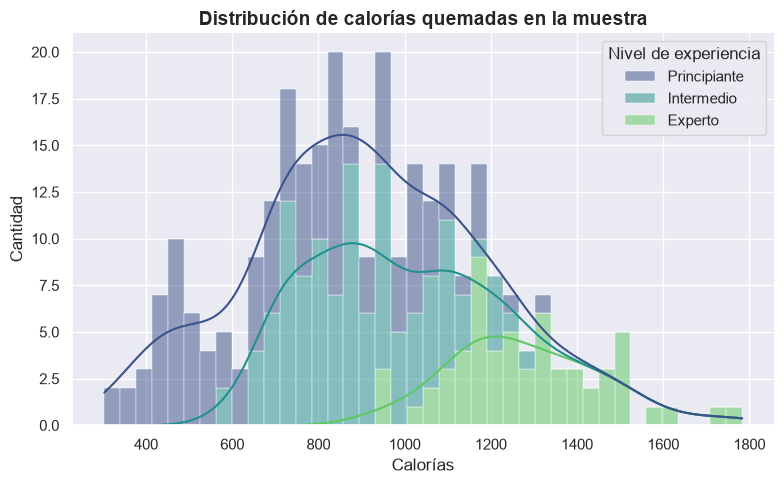

In [75]:
niveles = {'1': 'Principiante', '2': 'Intermedio', '3': 'Experto'}
muestra['Nivel'] = muestra['Experience_Level'].astype(str).map(niveles)

sns.set_theme(style='darkgrid')
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=muestra, x='Calories_Burned', hue='Nivel',
             hue_order=['Principiante', 'Intermedio', 'Experto'],
             bins=40, log_scale=False, stat='count',
             multiple='stack', element='bars', kde=True,
             palette='viridis', edgecolor='white', linewidth=0.3, ax=ax)

ax.set_title('Distribución de calorías quemadas en la muestra', fontsize=14, fontweight='bold')
ax.set_xlabel('Calorías')
ax.set_ylabel('Cantidad')
ax.get_legend().set_title('Nivel de experiencia')
sns.despine()
plt.tight_layout()
plt.show()

Observamos con el grafico de caja la relacion  entre gasto calorico y nivel de experiencia, y comprobamos si existe una diferencia marcada entre géneros.

Los valores máximos en cuanto a gasto calorico son alcanzados pr los hombres expertos, y en general, los valores maximos les corresponden a los hombres.

Los valores de mediana son mas parejos para hombres y mujeres principiantes e intermedios.
Donde se encuentra la mayor diferencia de gasto observando la mediana es el el grupo de principiantes, no solo tienen los rangos mas amplios para su propio genero, sino que la mediana comparando generos es mas dispareja que comparando por género para los niveles de experiencia mas altos.

Esto puede deberse a multiples factores que caracterizan a los principiantes y que determinan el output de esfuerzo que pueden realizar y por lo tanto el gasto calórico.

Contrario en los niveles mas altos donde se estima un mejor manejo de los elementos de entrenamiento, cargas y técnicas que permiten un output mayor, y ademas provoca que los rangos de gasto sean mas parejos al comparar entre generos.

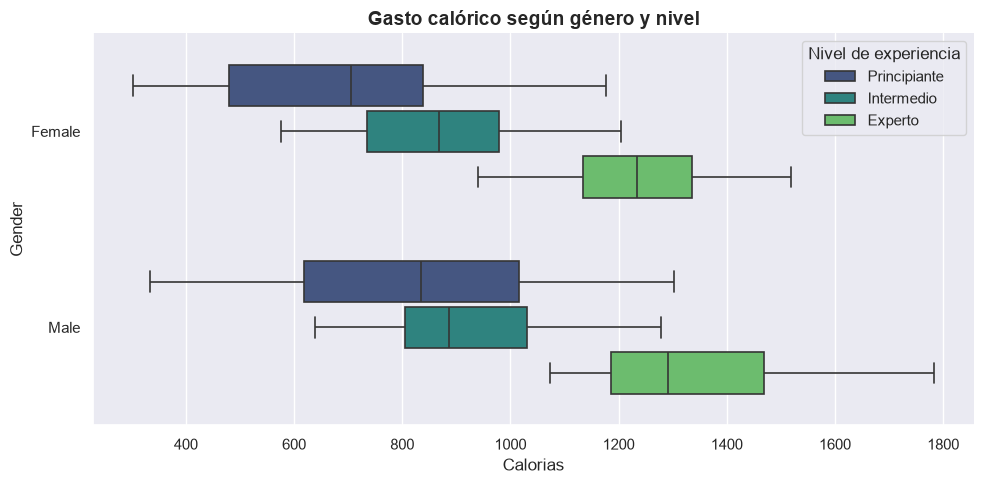

In [73]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style='darkgrid')
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=muestra, x='Calories_Burned', y='Gender', hue='Nivel',
            hue_order=['Principiante', 'Intermedio', 'Experto'],
            palette='viridis', width=0.7, gap=0.1, whis=1.5,
            fliersize=4, linewidth=1.2, ax=ax)

ax.set_title('Gasto calórico según género y nivel', fontsize=14, fontweight='bold')
ax.set_xlabel('Calorias')
ax.legend(title='Nivel de experiencia', loc='upper right')
sns.despine()

plt.tight_layout()
plt.show()


## Workout_Type y Gasto

In [76]:
muestra.head(2)

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI,Nivel
471,43,Female,73.0,1.59,191,158,67,1.31,931.0,Yoga,28.9,2.2,3,1,28.88,Principiante
64,31,Female,64.4,1.70,160,144,70,1.97,1418.0,Strength,17.3,2.7,5,3,22.28,Experto


In [81]:
muestra['Workout_Type'].unique()

<StringArray>
['Yoga', 'Strength', 'HIIT', 'Cardio']
Length: 4, dtype: str

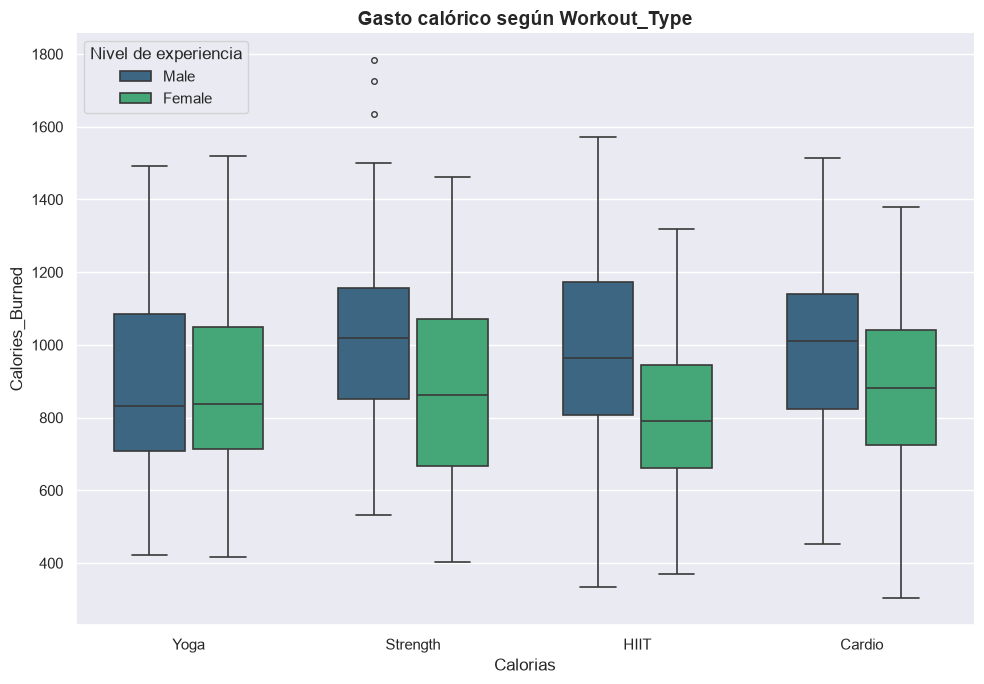

In [87]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style='darkgrid')
fig, ax = plt.subplots(figsize=(10, 7))
sns.boxplot(data=muestra, y='Calories_Burned', x='Workout_Type', hue='Gender',
            hue_order=['Male', 'Female'],
            palette='viridis', width=0.7, gap=0.1, whis=1.5,
            fliersize=4, linewidth=1.2, ax=ax)

ax.set_title('Gasto calórico según Workout_Type', fontsize=14, fontweight='bold')
ax.set_xlabel('Calorias')
ax.legend(title='Nivel de experiencia', loc='upper left')
sns.despine()

plt.tight_layout()
plt.show()

In [ ]:
otliers = muestra['']

In [ ]:
outliers = muestra.loc[
    (muestra['Workout_Type'] == 'Strength') &
    (muestra['Calories_Burned'] > 1500)
]

outliers